# Facial Region Masks with RetinaFace
This notebook uses RetinaFace for robust facial landmark detection even with head turning.

## Objectives:
1. Setup RetinaFace with ResNet50 weights
2. Test landmark detection on turning face
3. Generate non-overlapping masks for real face
4. Generate overlapping masks for real face
5. Compare real vs fake (FaceShifter) masks

**Key Advantage:** RetinaFace provides 5 landmarks that are robust to pose variations

In [1]:
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import torch
import pickle
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.9.1
CUDA available: False


## 1. Setup RetinaFace

In [2]:
# Clone RetinaFace repository
!git clone https://github.com/biubug6/Pytorch_Retinaface.git

# Add to path
sys.path.append('Pytorch_Retinaface')

Cloning into 'Pytorch_Retinaface'...
remote: Enumerating objects: 123, done.
remote: Total 123 (delta 0), reused 0 (delta 0), pack-reused 123 (from 1)
Receiving objects: 100% (123/123), 6.81 MiB | 2.96 MiB/s, done.
Resolving deltas: 100% (41/41), done.


In [3]:
# Download ResNet50 weights
!mkdir -p weights
!wget -O weights/Resnet50_Final.pth https://github.com/elliottzheng/face-detection/releases/download/0.0.1/Resnet50_Final.pth

print("✓ Downloaded ResNet50 weights")

--2026-02-20 16:59:18--  https://github.com/elliottzheng/face-detection/releases/download/0.0.1/Resnet50_Final.pth
Resolving github.com (github.com)... 140.82.121.4
Connecting to github.com (github.com)|140.82.121.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/233762891/96c601f5-fc5a-4821-9ac6-c85309e5af60?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-02-20T16%3A47%3A08Z&rscd=attachment%3B+filename%3DResnet50_Final.pth&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-02-20T15%3A47%3A07Z&ske=2026-02-20T16%3A47%3A08Z&sks=b&skv=2018-11-09&sig=stkujO2lKCGfZiNr1ft%2Ba8dy%2B3ULALw9L59gAgqX5Cw%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc3MTYwNjc1OCwibmJmIjoxNzcxNjAzMTU4LCJwYXRoIjoicmVsZWFzZWFzc2V0c

In [4]:
# Import RetinaFace modules
from models.retinaface import RetinaFace
from data import cfg_re50
from layers.functions.prior_box import PriorBox
from utils.nms.py_cpu_nms import py_cpu_nms
from utils.box_utils import decode, decode_landm

# Configuration
cfg = cfg_re50
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [6]:
# Load RetinaFace model
def load_retinaface_model(weight_path, device):
    """Load RetinaFace model with ResNet50 backbone."""
    net = RetinaFace(cfg=cfg, phase='test')
    net = net.to(device)
    
    # Load weights
    checkpoint = torch.load(weight_path, map_location=device)
    
    # Remove 'module.' prefix from DataParallel checkpoint
    from collections import OrderedDict
    new_state_dict = OrderedDict()
    for k, v in checkpoint.items():
        name = k[7:] if k.startswith('module.') else k  # remove 'module.' prefix
        new_state_dict[name] = v
    
    net.load_state_dict(new_state_dict)
    net.eval()
    
    print("✓ RetinaFace model loaded successfully")
    return net

# Load model
retinaface_model = load_retinaface_model('weights/Resnet50_Final.pth', device)

✓ RetinaFace model loaded successfully


## 2. RetinaFace Landmark Detection Function
RetinaFace provides 5 landmarks:
- 0: Left Eye
- 1: Right Eye  
- 2: Nose
- 3: Left Mouth Corner
- 4: Right Mouth Corner

In [7]:
def detect_faces_retinaface(image, model, device, confidence_threshold=0.5):
    """Detect faces and landmarks using RetinaFace."""
    img_raw = image.copy()
    img = np.float32(img_raw)
    
    # Normalize
    im_height, im_width, _ = img.shape
    scale = torch.Tensor([img.shape[1], img.shape[0], img.shape[1], img.shape[0]])
    img -= (104, 117, 123)
    img = img.transpose(2, 0, 1)
    img = torch.from_numpy(img).unsqueeze(0)
    img = img.to(device)
    scale = scale.to(device)
    
    # Forward pass
    with torch.no_grad():
        loc, conf, landms = model(img)
    
    # Prior boxes
    priorbox = PriorBox(cfg, image_size=(im_height, im_width))
    priors = priorbox.forward()
    priors = priors.to(device)
    prior_data = priors.data
    
    # Decode boxes
    boxes = decode(loc.data.squeeze(0), prior_data, cfg['variance'])
    boxes = boxes * scale
    boxes = boxes.cpu().numpy()
    
    # Decode landmarks
    landms = decode_landm(landms.data.squeeze(0), prior_data, cfg['variance'])
    scale1 = torch.Tensor([img.shape[3], img.shape[2], img.shape[3], img.shape[2],
                           img.shape[3], img.shape[2], img.shape[3], img.shape[2],
                           img.shape[3], img.shape[2]])
    scale1 = scale1.to(device)
    landms = landms * scale1
    landms = landms.cpu().numpy()
    
    # Confidence scores
    scores = conf.squeeze(0).data.cpu().numpy()[:, 1]
    
    # Filter by confidence
    inds = np.where(scores > confidence_threshold)[0]
    boxes = boxes[inds]
    landms = landms[inds]
    scores = scores[inds]
    
    # NMS
    order = scores.argsort()[::-1]
    boxes = boxes[order]
    landms = landms[order]
    scores = scores[order]
    
    dets = np.hstack((boxes, scores[:, np.newaxis])).astype(np.float32, copy=False)
    keep = py_cpu_nms(dets, 0.4)
    dets = dets[keep, :]
    landms = landms[keep]
    
    if len(dets) == 0:
        return None, None
    
    # Return first face (highest confidence)
    landmarks = landms[0].reshape(5, 2)
    bbox = dets[0][:4]
    
    return landmarks, bbox

def extract_retinaface_landmarks(image_path, model, device):
    """Extract RetinaFace landmarks from image path."""
    img = cv2.imread(str(image_path))
    if img is None:
        return None, None
    
    landmarks, bbox = detect_faces_retinaface(img, model, device)
    return landmarks, img

print("✓ RetinaFace detection functions defined")

✓ RetinaFace detection functions defined


## 3. Test on Turning Face

Found 128 frames
Processing turning face frames...
  Processed 20/128 frames...
  Processed 40/128 frames...
  Processed 60/128 frames...
  Processed 80/128 frames...
  Processed 100/128 frames...
  Processed 120/128 frames...
✓ Extracted landmarks from 128/128 frames
Landmarks shape: (128, 5, 2)

Median landmark positions:
0: Left Eye        (90, 83)
1: Right Eye       (171, 84)
2: Nose            (132, 124)
3: Left Mouth      (96, 181)
4: Right Mouth     (164, 179)


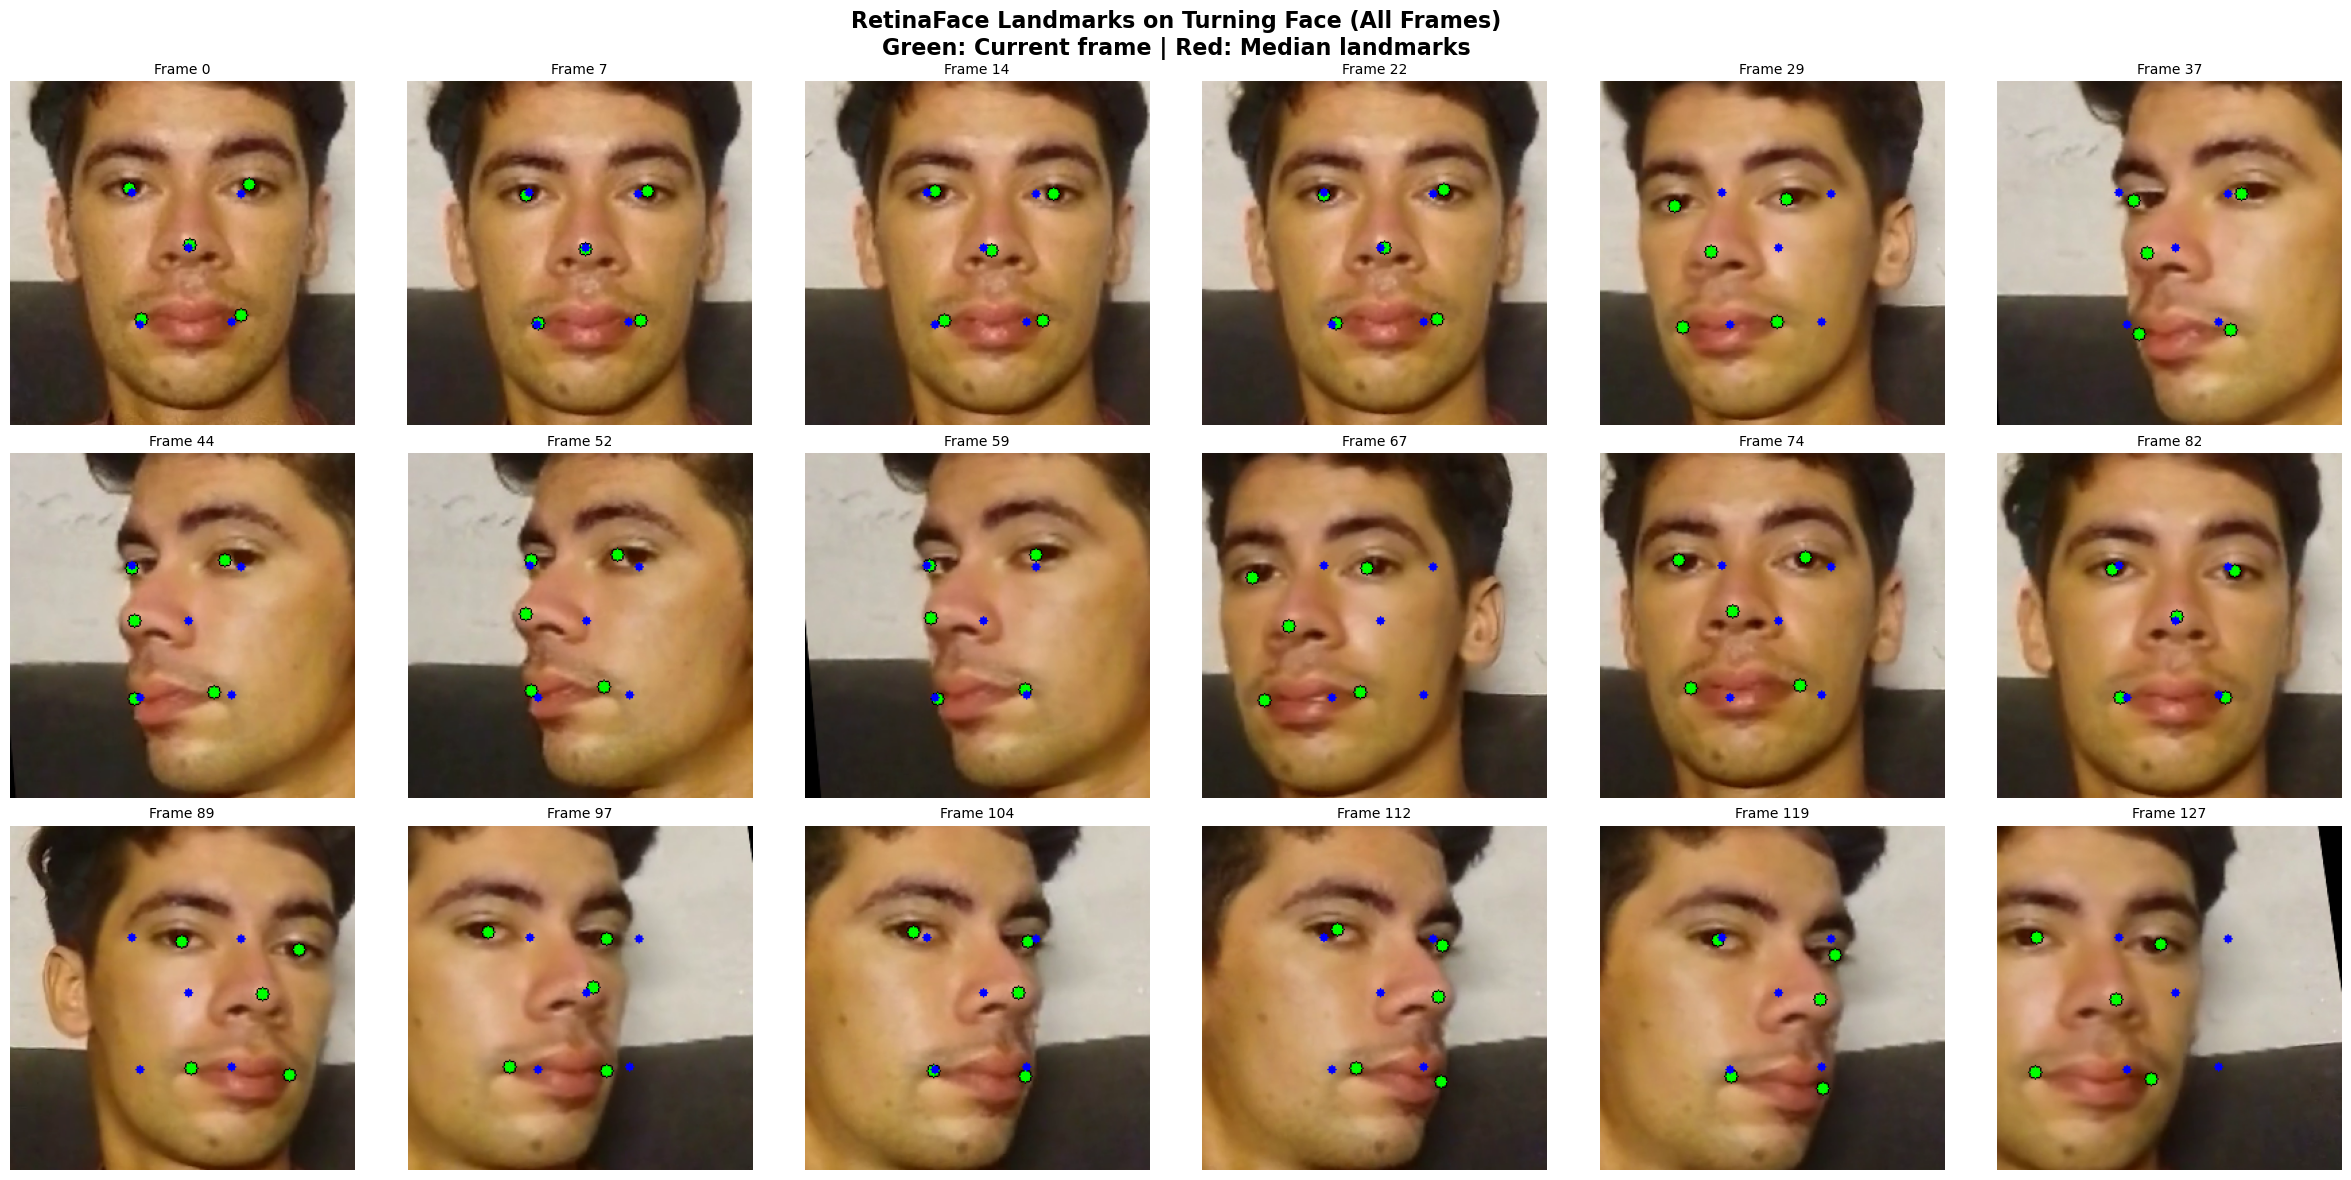

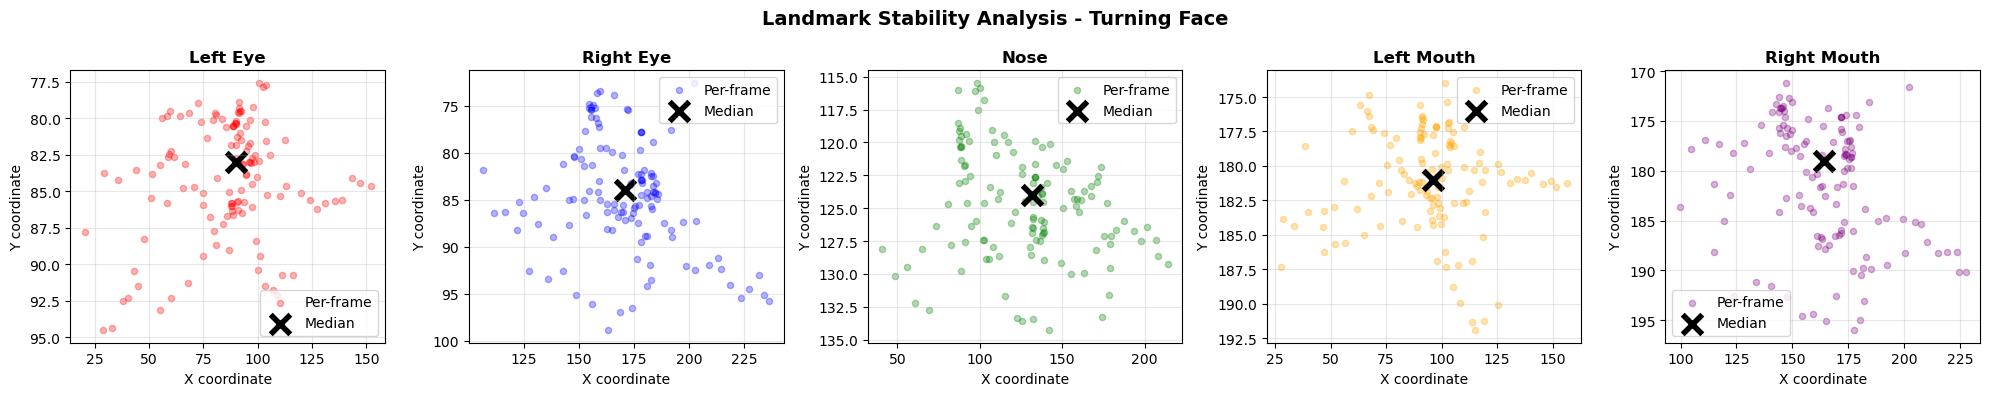

In [26]:
# Test on turning face - Process ALL frames
turning_face_dir = Path('/Users/mac/Documents/FMT/Tourning-fake-face/1')

# Get all frames (00_0000.png to 00_0127.png)
turning_image_files = sorted(list(turning_face_dir.glob('00_*.png')))
print(f"Found {len(turning_image_files)} frames")

# Extract landmarks from all frames
all_turning_landmarks = []
valid_turning_images = []

print("Processing turning face frames...")
for i, img_path in enumerate(turning_image_files):
    landmarks, img = extract_retinaface_landmarks(img_path, retinaface_model, device)
    if landmarks is not None:
        all_turning_landmarks.append(landmarks)
        valid_turning_images.append(img_path)
    
    if (i + 1) % 20 == 0:
        print(f"  Processed {i+1}/{len(turning_image_files)} frames...")

all_turning_landmarks = np.array(all_turning_landmarks)
print(f"✓ Extracted landmarks from {len(all_turning_landmarks)}/{len(turning_image_files)} frames")
print(f"Landmarks shape: {all_turning_landmarks.shape}")

# Calculate median landmarks
turning_median_landmarks = np.median(all_turning_landmarks, axis=0).astype(np.int32)
print(f"\nMedian landmark positions:")
landmark_names = ['Left Eye', 'Right Eye', 'Nose', 'Left Mouth', 'Right Mouth']
for i, (name, (x, y)) in enumerate(zip(landmark_names, turning_median_landmarks)):
    print(f"{i}: {name:<15} ({x}, {y})")

# Display 18 frames with landmarks
n_display = 18
n_cols = 6
n_rows = 3

# Select evenly spaced frames
frame_indices = np.linspace(0, len(valid_turning_images)-1, n_display, dtype=int)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, 12))
axes = axes.flatten()

for idx, frame_idx in enumerate(frame_indices):
    ax = axes[idx]
    
    # Load image
    img = cv2.imread(str(valid_turning_images[frame_idx]))
    landmarks = all_turning_landmarks[frame_idx]
    
    # Draw landmarks
    vis = img.copy()
    for i, (x, y) in enumerate(landmarks):
        cv2.circle(vis, (int(x), int(y)), 4, (0, 255, 0), -1)
        cv2.circle(vis, (int(x), int(y)), 5, (0, 0, 0), 1)
    
    # Draw median landmarks in red
    for i, (x, y) in enumerate(turning_median_landmarks):
        cv2.circle(vis, (int(x), int(y)), 3, (255, 0, 0), -1)
    
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f'Frame {frame_idx}', fontsize=10)
    ax.axis('off')

plt.suptitle('RetinaFace Landmarks on Turning Face (All Frames)\nGreen: Current frame | Red: Median landmarks', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Visualize landmark stability for turning face
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

colors = ['red', 'blue', 'green', 'orange', 'purple']

for lm_idx, (name, color, ax) in enumerate(zip(landmark_names, colors, axes)):
    # Plot all positions
    x_coords = all_turning_landmarks[:, lm_idx, 0]
    y_coords = all_turning_landmarks[:, lm_idx, 1]
    
    ax.scatter(x_coords, y_coords, alpha=0.3, s=20, c=color, label='Per-frame')
    ax.scatter(turning_median_landmarks[lm_idx, 0], turning_median_landmarks[lm_idx, 1], 
              c='black', s=200, marker='x', linewidths=4, label='Median')
    
    ax.set_title(f'{name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('X coordinate')
    ax.set_ylabel('Y coordinate')
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle('Landmark Stability Analysis - Turning Face', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Extract Landmarks from Video Frames (Real Face)

In [10]:
def collect_retinaface_landmarks(video_path, model, device):
    """Collect RetinaFace landmarks from all frames in a video folder."""
    image_files = sorted(list(video_path.glob('*.png')) + list(video_path.glob('*.jpg')))
    
    all_landmarks = []
    valid_images = []
    
    print(f"Processing {len(image_files)} frames...")
    for i, img_path in enumerate(image_files):
        landmarks, img = extract_retinaface_landmarks(img_path, model, device)
        if landmarks is not None:
            all_landmarks.append(landmarks)
            valid_images.append(img_path)
        
        if (i + 1) % 20 == 0:
            print(f"  Processed {i+1}/{len(image_files)} frames...")
    
    print(f"✓ Extracted landmarks from {len(all_landmarks)}/{len(image_files)} frames")
    return np.array(all_landmarks), valid_images

# Extract landmarks from real face
BASE_DIR = Path('/Users/mac/Documents/FMT/original-faces')
VIDEO_ID = '000'
REAL_VIDEO_PATH = BASE_DIR / VIDEO_ID

print("\n=== Processing REAL face ===")
real_landmarks, real_images = collect_retinaface_landmarks(REAL_VIDEO_PATH, retinaface_model, device)
print(f"Real landmarks shape: {real_landmarks.shape}")


=== Processing REAL face ===
Processing 128 frames...
  Processed 20/128 frames...
  Processed 40/128 frames...
  Processed 60/128 frames...
  Processed 80/128 frames...
  Processed 100/128 frames...
  Processed 120/128 frames...
✓ Extracted landmarks from 128/128 frames
Real landmarks shape: (128, 5, 2)


## 5. Extract Landmarks from Fake Face (FaceShifter)

In [11]:
# Extract landmarks from fake face
FAKE_VIDEO_PATH = Path('/Users/mac/Documents/FMT/fake-faces/FaceShifter/000')

print("\n=== Processing FAKE face (FaceShifter) ===")
fake_landmarks, fake_images = collect_retinaface_landmarks(FAKE_VIDEO_PATH, retinaface_model, device)
print(f"Fake landmarks shape: {fake_landmarks.shape}")


=== Processing FAKE face (FaceShifter) ===
Processing 128 frames...
  Processed 20/128 frames...
  Processed 40/128 frames...
  Processed 60/128 frames...
  Processed 80/128 frames...
  Processed 100/128 frames...
  Processed 120/128 frames...
✓ Extracted landmarks from 128/128 frames
Fake landmarks shape: (128, 5, 2)


## 6. Calculate Median Landmarks

In [25]:
# Calculate median landmarks for both
real_median_landmarks = np.median(real_landmarks, axis=0).astype(np.int32)
fake_median_landmarks = np.median(fake_landmarks, axis=0).astype(np.int32)

print("Real median landmarks:")
for i, (x, y) in enumerate(real_median_landmarks):
    print(f"  {i}: ({x}, {y})")

print("\nFake median landmarks:")
for i, (x, y) in enumerate(fake_median_landmarks):
    print(f"  {i}: ({x}, {y})")


Real median landmarks:
  0: (86, 79)
  1: (173, 78)
  2: (129, 128)
  3: (98, 180)
  4: (162, 178)

Fake median landmarks:
  0: (85, 79)
  1: (172, 80)
  2: (128, 128)
  3: (96, 177)
  4: (163, 176)


## 7. Define Facial Regions from 5 Landmarks
With only 5 landmarks, we define simplified but robust regions

In [14]:
def create_extended_regions(landmarks, image_shape):
    """
    Create facial regions from 5 RetinaFace landmarks.
    Landmarks: 0=L_eye, 1=R_eye, 2=Nose, 3=L_mouth, 4=R_mouth
    """
    h, w = image_shape[:2]
    
    # Extract landmark positions
    l_eye = landmarks[0]  # Left eye
    r_eye = landmarks[1]  # Right eye
    nose = landmarks[2]   # Nose tip
    l_mouth = landmarks[3]  # Left mouth corner
    r_mouth = landmarks[4]  # Right mouth corner
    
    # Calculate helper points
    eye_center = (l_eye + r_eye) / 2
    mouth_center = (l_mouth + r_mouth) / 2
    face_center = (eye_center + mouth_center) / 2
    
    # Calculate face dimensions
    eye_dist = np.linalg.norm(r_eye - l_eye)
    eye_to_mouth = np.linalg.norm(mouth_center - eye_center)
    
    # Define regions (each as polygon vertices)
    regions = {}
    
    # 1. Left Eye Region (circular area around left eye)
    eye_radius = int(eye_dist * 0.25)
    regions['left_eye'] = create_circle_polygon(l_eye, eye_radius)
    
    # 2. Right Eye Region
    regions['right_eye'] = create_circle_polygon(r_eye, eye_radius)
    
    # 3. Nose Region (triangle from eyes to nose)
    nose_top = eye_center
    nose_width = eye_dist * 0.3
    regions['nose'] = np.array([
        nose_top + [-nose_width/2, 0],
        nose_top + [nose_width/2, 0],
        nose + [nose_width/2, 0],
        nose + [-nose_width/2, 0]
    ], dtype=np.int32)
    
    # 4. Mouth Region (ellipse around mouth)
    mouth_width = np.linalg.norm(r_mouth - l_mouth) * 1.2
    mouth_height = mouth_width * 0.6
    regions['mouth'] = create_ellipse_polygon(mouth_center, mouth_width, mouth_height)
    
    # 5. Left Cheek (between left eye and left mouth)
    cheek_offset = eye_dist * 0.4
    regions['left_cheek'] = np.array([
        l_eye + [-cheek_offset, eye_radius],
        l_eye + [0, eye_radius*2],
        l_mouth + [0, -eye_radius],
        l_mouth + [-cheek_offset, 0]
    ], dtype=np.int32)
    
    # 6. Right Cheek
    regions['right_cheek'] = np.array([
        r_eye + [cheek_offset, eye_radius],
        r_eye + [0, eye_radius*2],
        r_mouth + [0, -eye_radius],
        r_mouth + [cheek_offset, 0]
    ], dtype=np.int32)
    
    # 7. Forehead (above eyes)
    forehead_height = eye_to_mouth * 0.8
    forehead_width = eye_dist * 1.8
    regions['forehead'] = np.array([
        eye_center + [-forehead_width/2, -forehead_height],
        eye_center + [forehead_width/2, -forehead_height],
        r_eye + [eye_radius, -eye_radius],
        l_eye + [-eye_radius, -eye_radius]
    ], dtype=np.int32)
    
    # 8. Chin (below mouth)
    chin_height = eye_to_mouth * 0.6
    chin_width = eye_dist * 1.2
    regions['chin'] = np.array([
        l_mouth + [0, 0],
        r_mouth + [0, 0],
        mouth_center + [chin_width/2, chin_height],
        mouth_center + [-chin_width/2, chin_height]
    ], dtype=np.int32)
    
    return regions

def create_circle_polygon(center, radius, n_points=16):
    """Create circular polygon."""
    angles = np.linspace(0, 2*np.pi, n_points, endpoint=False)
    points = np.array([
        [center[0] + radius * np.cos(a), center[1] + radius * np.sin(a)]
        for a in angles
    ], dtype=np.int32)
    return points

def create_ellipse_polygon(center, width, height, n_points=16):
    """Create elliptical polygon."""
    angles = np.linspace(0, 2*np.pi, n_points, endpoint=False)
    points = np.array([
        [center[0] + width/2 * np.cos(a), center[1] + height/2 * np.sin(a)]
        for a in angles
    ], dtype=np.int32)
    return points

print("✓ Region creation functions defined")

✓ Region creation functions defined


## 8. Generate Non-Overlapping Masks

In [15]:
# Region colors and priorities
REGION_CONFIG = {
    'left_eye': {'priority': 1, 'color': (255, 0, 0)},
    'right_eye': {'priority': 1, 'color': (255, 0, 0)},
    'mouth': {'priority': 2, 'color': (255, 255, 0)},
    'nose': {'priority': 3, 'color': (0, 0, 255)},
    'left_cheek': {'priority': 4, 'color': (255, 0, 255)},
    'right_cheek': {'priority': 4, 'color': (255, 0, 255)},
    'forehead': {'priority': 5, 'color': (0, 255, 255)},
    'chin': {'priority': 6, 'color': (128, 128, 128)}
}

def create_mask_from_polygon(polygon, image_shape):
    """Create binary mask from polygon."""
    mask = np.zeros(image_shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [polygon], 255)
    return mask

def generate_non_overlapping_masks(landmarks, image_shape, region_config):
    """Generate non-overlapping masks from landmarks."""
    # Create region polygons
    region_polygons = create_extended_regions(landmarks, image_shape)
    
    # Sort by priority
    sorted_regions = sorted(region_config.items(), key=lambda x: x[1]['priority'])
    
    masks = {}
    occupied = np.zeros(image_shape[:2], dtype=np.uint8)
    
    for region_name, config in sorted_regions:
        if region_name not in region_polygons:
            continue
            
        # Create mask
        mask = create_mask_from_polygon(region_polygons[region_name], image_shape)
        
        # Remove overlaps
        mask = cv2.bitwise_and(mask, cv2.bitwise_not(occupied))
        
        # Update occupied
        occupied = cv2.bitwise_or(occupied, mask)
        
        masks[region_name] = mask
        print(f"{region_name:<15} Priority:{config['priority']:<3} Pixels:{np.sum(mask > 0):>6}")
    
    return masks, occupied

# Generate for real face
real_img_first = cv2.imread(str(real_images[0]))
real_image_shape = real_img_first.shape

print("\n=== Generating Non-Overlapping Masks (REAL) ===")
real_masks_no_overlap, real_occupied = generate_non_overlapping_masks(
    real_median_landmarks, real_image_shape, REGION_CONFIG
)

# Generate for fake face
fake_img_first = cv2.imread(str(fake_images[0]))
fake_image_shape = fake_img_first.shape

print("\n=== Generating Non-Overlapping Masks (FAKE) ===")
fake_masks_no_overlap, fake_occupied = generate_non_overlapping_masks(
    fake_median_landmarks, fake_image_shape, REGION_CONFIG
)


=== Generating Non-Overlapping Masks (REAL) ===
left_eye        Priority:1   Pixels:  1412
right_eye       Priority:1   Pixels:  1412
mouth           Priority:2   Pixels:  2833
nose            Priority:3   Pixels:  1403
left_cheek      Priority:4   Pixels:  2162
right_cheek     Priority:4   Pixels:  2064
forehead        Priority:5   Pixels:  8377
chin            Priority:6   Pixels:  3863

=== Generating Non-Overlapping Masks (FAKE) ===
left_eye        Priority:1   Pixels:  1412
right_eye       Priority:1   Pixels:  1412
mouth           Priority:2   Pixels:  3009
nose            Priority:3   Pixels:  1375
left_cheek      Priority:4   Pixels:  2052
right_cheek     Priority:4   Pixels:  1924
forehead        Priority:5   Pixels:  8376
chin            Priority:6   Pixels:  3623


## 9. Generate Overlapping Masks

In [16]:
def generate_overlapping_masks(landmarks, image_shape, region_config):
    """Generate overlapping masks from landmarks."""
    # Create region polygons
    region_polygons = create_extended_regions(landmarks, image_shape)
    
    masks = {}
    
    for region_name in region_config.keys():
        if region_name not in region_polygons:
            continue
            
        # Create mask (no overlap removal)
        mask = create_mask_from_polygon(region_polygons[region_name], image_shape)
        masks[region_name] = mask
        
        print(f"{region_name:<15} Pixels:{np.sum(mask > 0):>6}")
    
    return masks

# Generate for real face
print("\n=== Generating Overlapping Masks (REAL) ===")
real_masks_overlap = generate_overlapping_masks(
    real_median_landmarks, real_image_shape, REGION_CONFIG
)

# Generate for fake face
print("\n=== Generating Overlapping Masks (FAKE) ===")
fake_masks_overlap = generate_overlapping_masks(
    fake_median_landmarks, fake_image_shape, REGION_CONFIG
)


=== Generating Overlapping Masks (REAL) ===
left_eye        Pixels:  1412
right_eye       Pixels:  1412
mouth           Pixels:  2833
nose            Pixels:  1403
left_cheek      Pixels:  2162
right_cheek     Pixels:  2064
forehead        Pixels:  8395
chin            Pixels:  5214

=== Generating Overlapping Masks (FAKE) ===
left_eye        Pixels:  1412
right_eye       Pixels:  1412
mouth           Pixels:  3009
nose            Pixels:  1375
left_cheek      Pixels:  2052
right_cheek     Pixels:  1924
forehead        Pixels:  8394
chin            Pixels:  5060


## 10. Visualize: Real vs Fake Comparison

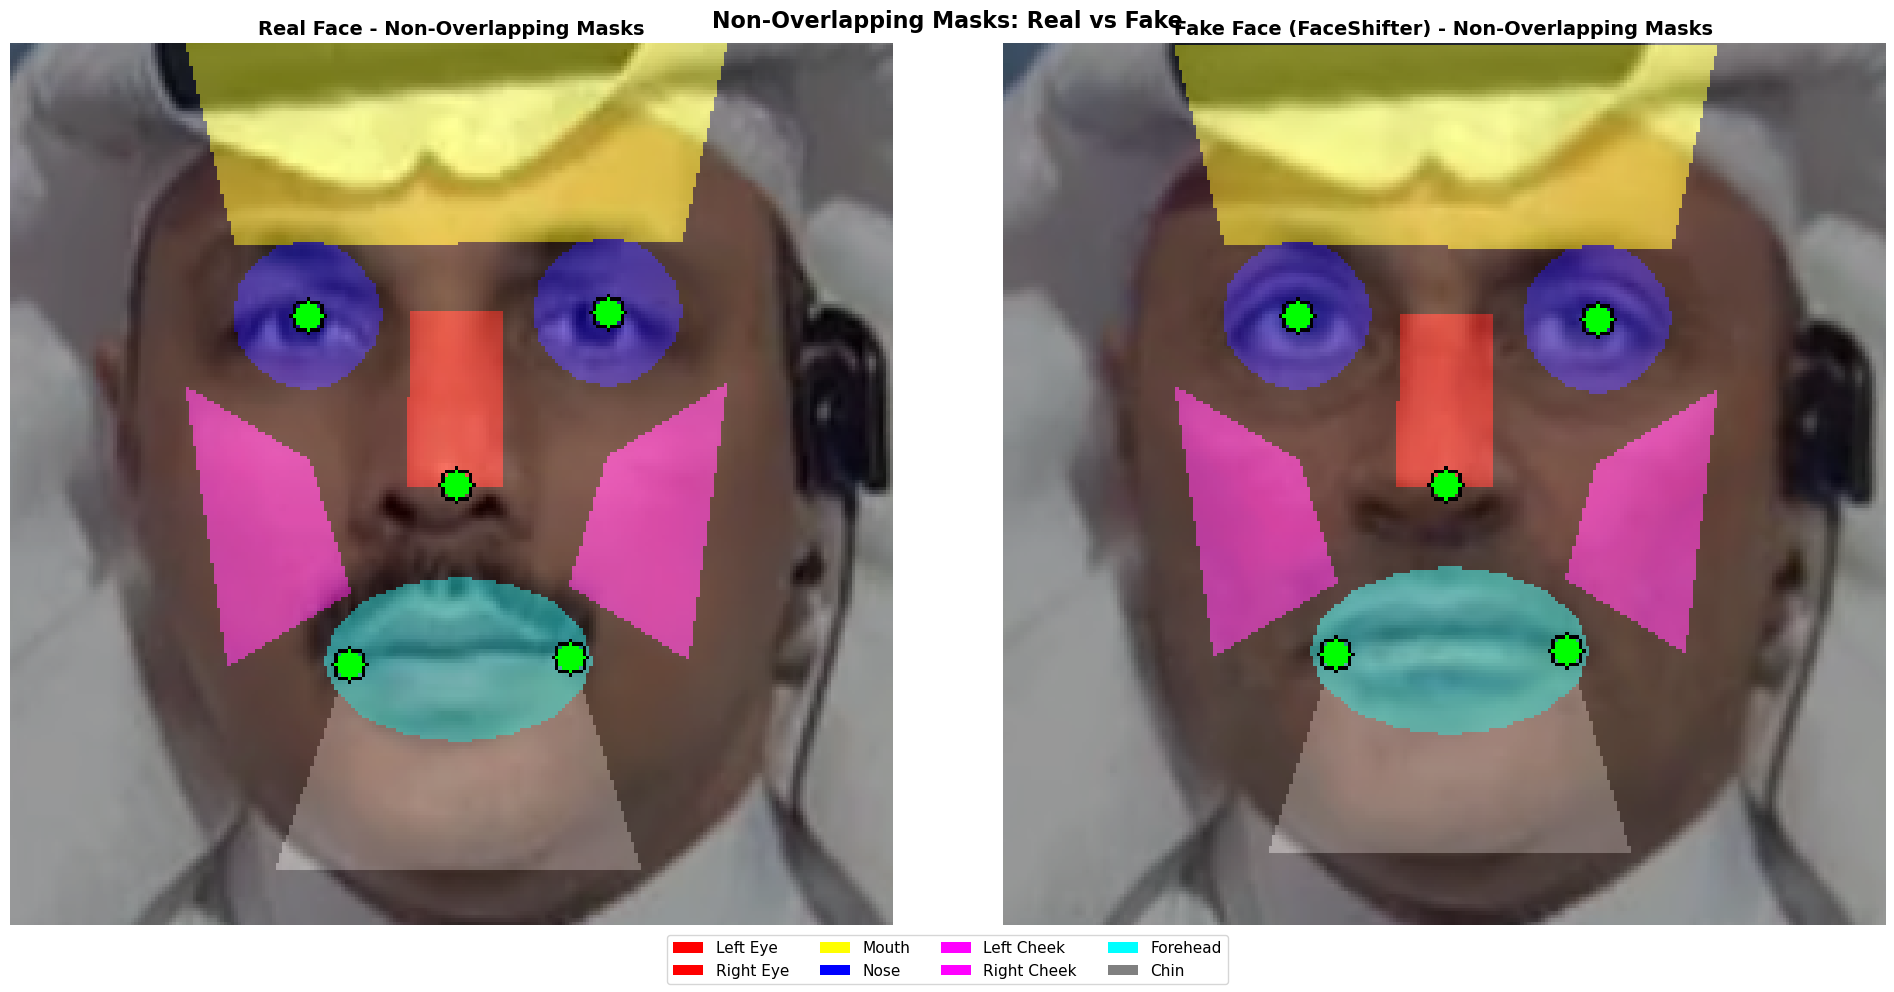

In [18]:
def visualize_masks_on_image(image, masks, region_config, landmarks, title):
    """Visualize masks overlaid on image."""
    result = image.copy()
    combined = np.zeros_like(image)
    
    for region_name, mask in masks.items():
        color = region_config[region_name]['color']
        colored = np.zeros_like(image)
        colored[mask > 0] = color
        combined = cv2.add(combined, colored)
    
    result = cv2.addWeighted(result, 0.6, combined, 0.4, 0)
    
    # Draw landmarks
    for i, (x, y) in enumerate(landmarks):
        cv2.circle(result, (int(x), int(y)), 4, (0, 255, 0), -1)
        cv2.circle(result, (int(x), int(y)), 5, (0, 0, 0), 1)
    
    return result

# Visualize non-overlapping
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

real_vis_no = visualize_masks_on_image(real_img_first, real_masks_no_overlap, 
                                        REGION_CONFIG, real_median_landmarks, 'Real')
fake_vis_no = visualize_masks_on_image(fake_img_first, fake_masks_no_overlap, 
                                        REGION_CONFIG, fake_median_landmarks, 'Fake')

axes[0].imshow(cv2.cvtColor(real_vis_no, cv2.COLOR_BGR2RGB))
axes[0].set_title('Real Face - Non-Overlapping Masks', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(fake_vis_no, cv2.COLOR_BGR2RGB))
axes[1].set_title('Fake Face (FaceShifter) - Non-Overlapping Masks', fontsize=14, fontweight='bold')
axes[1].axis('off')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=np.array(config['color'])/255, label=name.replace('_', ' ').title())
    for name, config in REGION_CONFIG.items()
]
fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=11)

plt.suptitle('Non-Overlapping Masks: Real vs Fake', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

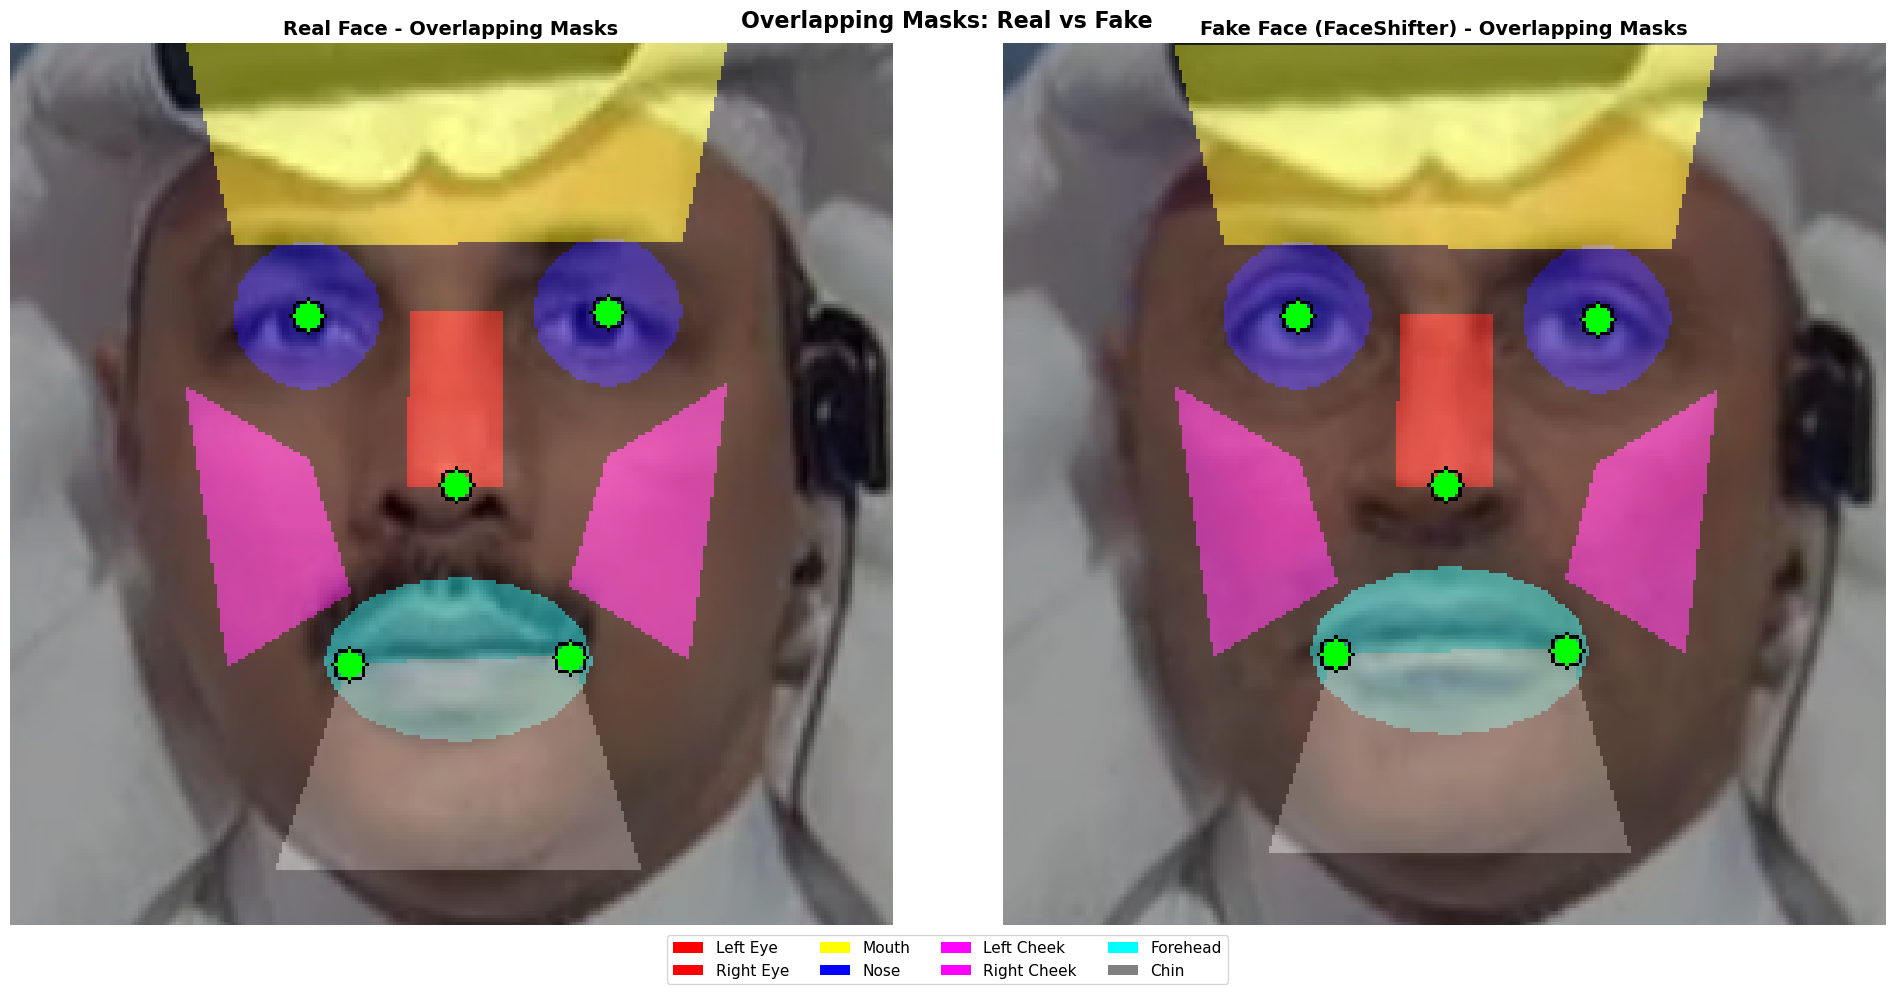

In [20]:
# Visualize overlapping
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

real_vis_ov = visualize_masks_on_image(real_img_first, real_masks_overlap, 
                                        REGION_CONFIG, real_median_landmarks, 'Real')
fake_vis_ov = visualize_masks_on_image(fake_img_first, fake_masks_overlap, 
                                        REGION_CONFIG, fake_median_landmarks, 'Fake')

axes[0].imshow(cv2.cvtColor(real_vis_ov, cv2.COLOR_BGR2RGB))
axes[0].set_title('Real Face - Overlapping Masks', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(fake_vis_ov, cv2.COLOR_BGR2RGB))
axes[1].set_title('Fake Face (FaceShifter) - Overlapping Masks', fontsize=14, fontweight='bold')
axes[1].axis('off')

fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=11)

plt.suptitle('Overlapping Masks: Real vs Fake', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

## 11. Stability Test Across Frames

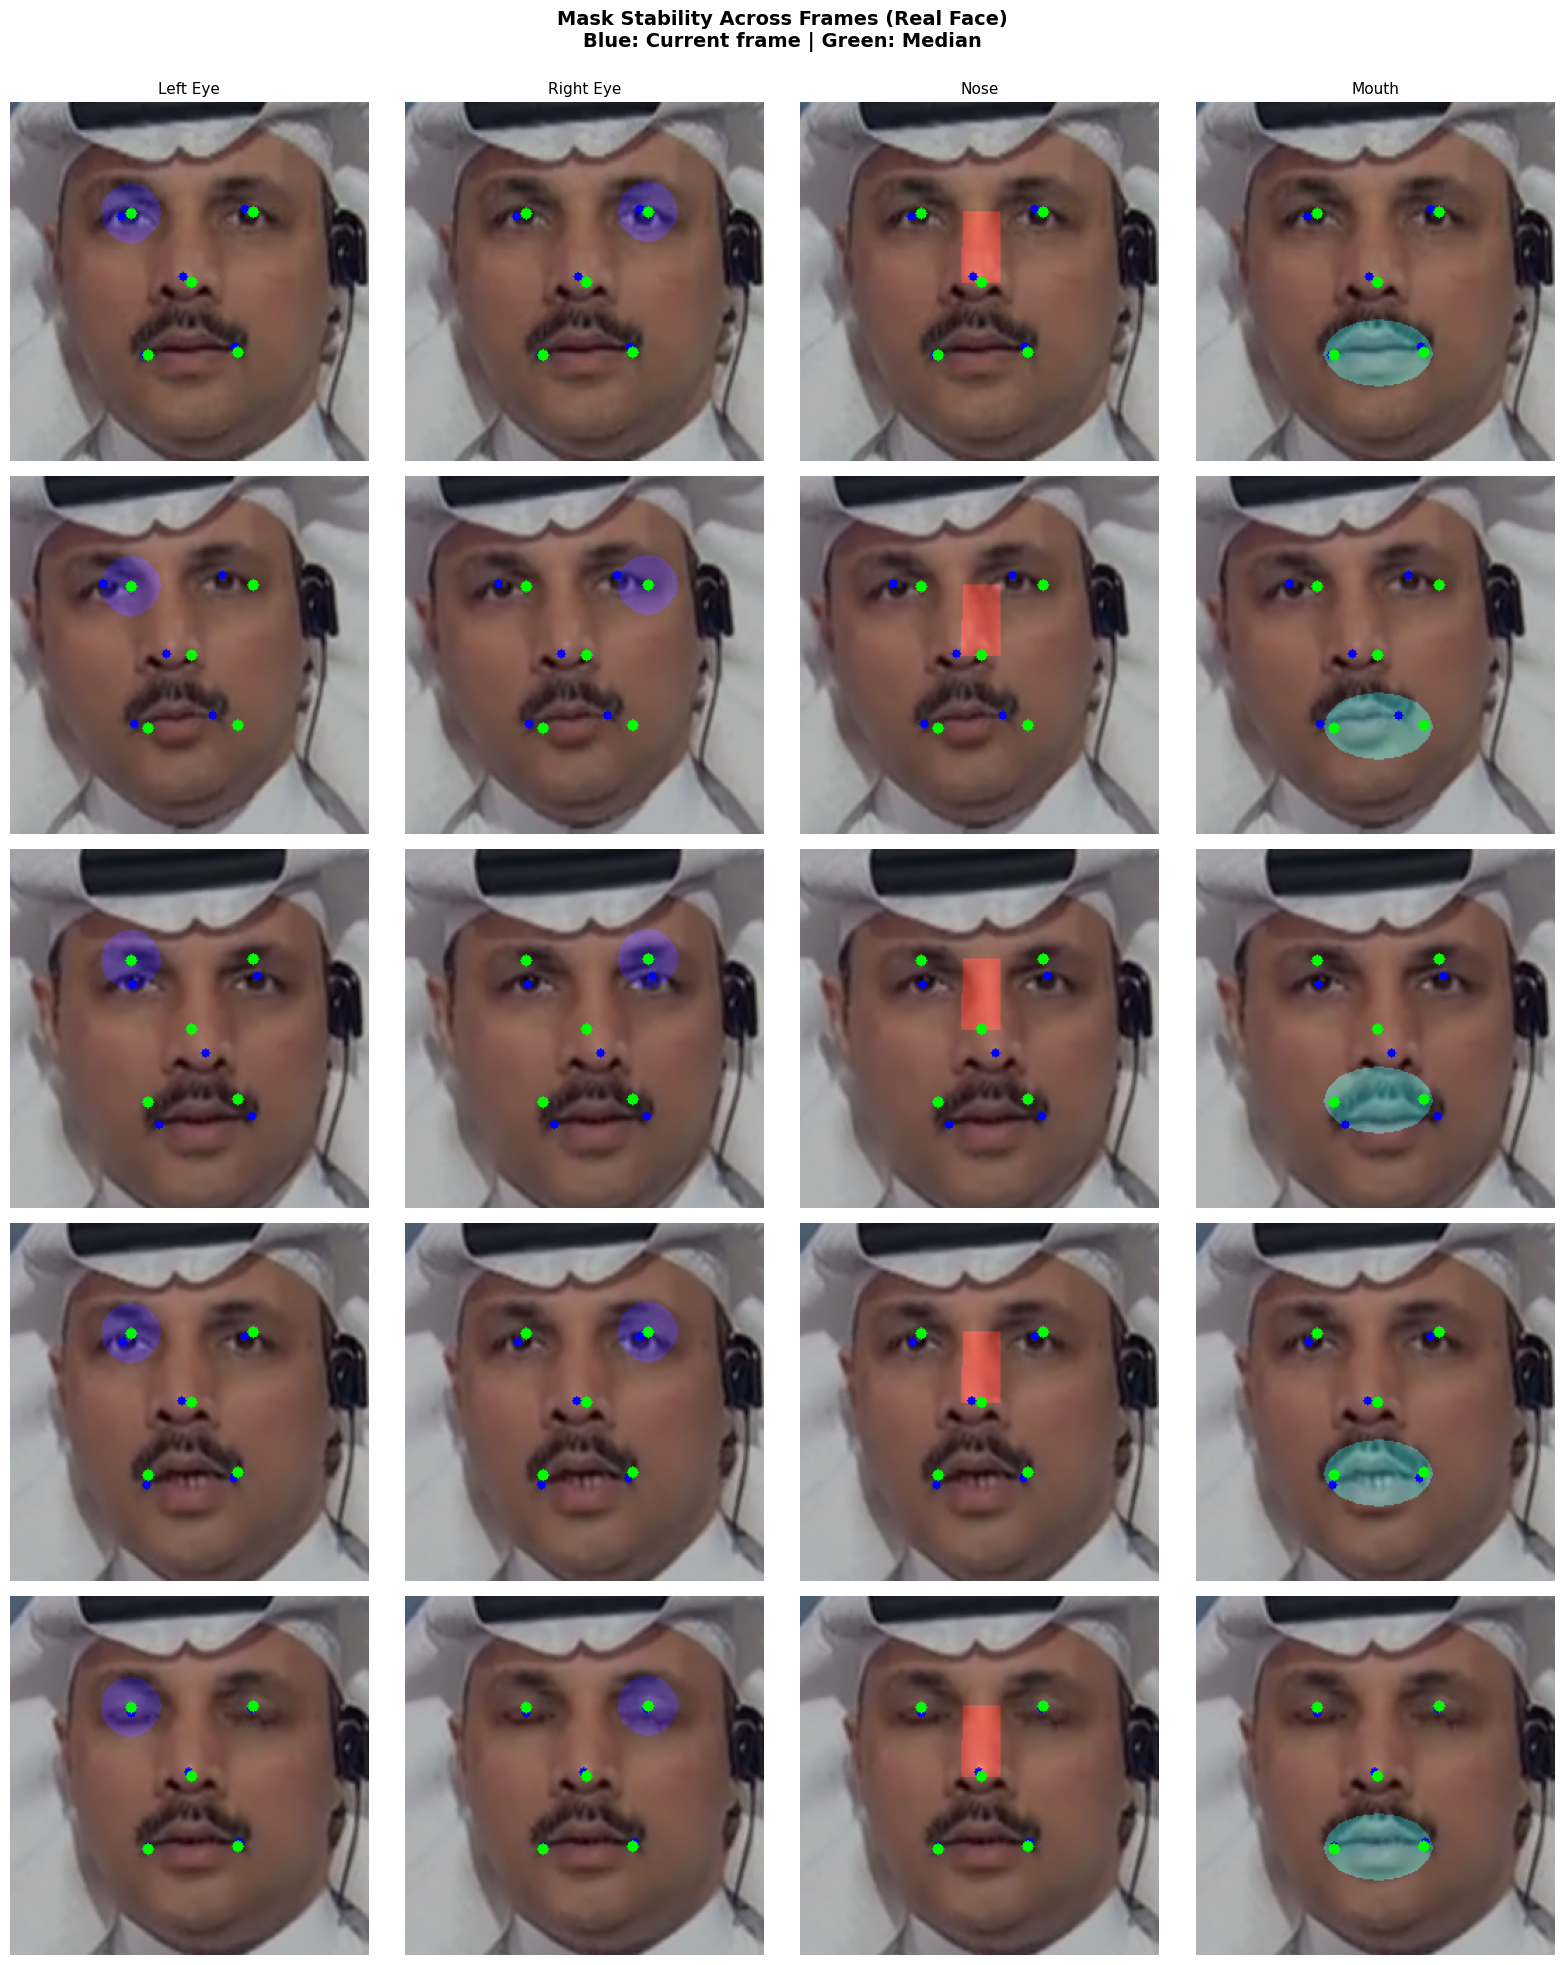

In [22]:
# Test stability on real face
n_frames = len(real_images)
test_indices = [0, n_frames//4, n_frames//2, 3*n_frames//4, n_frames-1]

key_regions = ['left_eye', 'right_eye', 'nose', 'mouth']

fig, axes = plt.subplots(len(test_indices), len(key_regions), figsize=(16, 4*len(test_indices)))

for row_idx, frame_idx in enumerate(test_indices):
    frame = cv2.imread(str(real_images[frame_idx]))
    current_landmarks = real_landmarks[frame_idx]
    
    for col_idx, region_name in enumerate(key_regions):
        ax = axes[row_idx, col_idx]
        
        if region_name not in real_masks_no_overlap:
            ax.axis('off')
            continue
        
        vis = frame.copy()
        mask = real_masks_no_overlap[region_name]
        colored = np.zeros_like(vis)
        color = REGION_CONFIG[region_name]['color']
        colored[mask > 0] = color
        result = cv2.addWeighted(vis, 0.7, colored, 0.3, 0)
        
        # Draw current landmarks (blue)
        for x, y in current_landmarks:
            cv2.circle(result, (int(x), int(y)), 3, (255, 0, 0), -1)
        
        # Draw median landmarks (green)
        for x, y in real_median_landmarks:
            cv2.circle(result, (int(x), int(y)), 4, (0, 255, 0), -1)
        
        ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
        
        if row_idx == 0:
            ax.set_title(region_name.replace('_', ' ').title(), fontsize=11)
        if col_idx == 0:
            ax.set_ylabel(f'Frame {frame_idx}', fontsize=11)
        ax.axis('off')

plt.suptitle('Mask Stability Across Frames (Real Face)\nBlue: Current frame | Green: Median', 
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

## 12. Save Results

In [ ]:
# Save real face data
real_data = {
    'video_id': VIDEO_ID,
    'type': 'real',
    'median_landmarks': real_median_landmarks,
    'masks_non_overlapping': real_masks_no_overlap,
    'masks_overlapping': real_masks_overlap,
    'region_config': REGION_CONFIG,
    'image_shape': real_image_shape,
    'detector': 'RetinaFace'
}

with open('/mnt/user-data/outputs/retinaface_real_masks.pkl', 'wb') as f:
    pickle.dump(real_data, f)

# Save fake face data
fake_data = {
    'video_id': VIDEO_ID,
    'type': 'fake_faceshifter',
    'median_landmarks': fake_median_landmarks,
    'masks_non_overlapping': fake_masks_no_overlap,
    'masks_overlapping': fake_masks_overlap,
    'region_config': REGION_CONFIG,
    'image_shape': fake_image_shape,
    'detector': 'RetinaFace'
}

with open('/mnt/user-data/outputs/retinaface_fake_masks.pkl', 'wb') as f:
    pickle.dump(fake_data, f)

print("✓ Saved mask data for both real and fake faces")

# Save individual mask images
for region_name, mask in real_masks_no_overlap.items():
    cv2.imwrite(f'/mnt/user-data/outputs/retinaface_real_no_overlap_{region_name}.png', mask)

for region_name, mask in fake_masks_no_overlap.items():
    cv2.imwrite(f'/mnt/user-data/outputs/retinaface_fake_no_overlap_{region_name}.png', mask)

print(f"✓ Saved {len(real_masks_no_overlap)} individual mask images")

## 13. Quantitative Comparison: Real vs Fake

In [23]:
# Compare landmark variance
print("\n=== Landmark Variance Analysis ===")
print(f"{'Landmark':<15} {'Real Var (X)':<15} {'Real Var (Y)':<15} {'Fake Var (X)':<15} {'Fake Var (Y)'}")
print("-" * 75)

for i, name in enumerate(['L Eye', 'R Eye', 'Nose', 'L Mouth', 'R Mouth']):
    real_var = np.var(real_landmarks[:, i, :], axis=0)
    fake_var = np.var(fake_landmarks[:, i, :], axis=0)
    print(f"{name:<15} {real_var[0]:<15.2f} {real_var[1]:<15.2f} {fake_var[0]:<15.2f} {fake_var[1]:<15.2f}")

# Compare mask coverage
print("\n=== Mask Coverage Comparison ===")
print(f"{'Region':<15} {'Real Pixels':<15} {'Fake Pixels':<15} {'Difference'}")
print("-" * 60)

for region_name in REGION_CONFIG.keys():
    if region_name in real_masks_no_overlap and region_name in fake_masks_no_overlap:
        real_px = np.sum(real_masks_no_overlap[region_name] > 0)
        fake_px = np.sum(fake_masks_no_overlap[region_name] > 0)
        diff = fake_px - real_px
        print(f"{region_name:<15} {real_px:<15} {fake_px:<15} {diff:+}")


=== Landmark Variance Analysis ===
Landmark        Real Var (X)    Real Var (Y)    Fake Var (X)    Fake Var (Y)
---------------------------------------------------------------------------
L Eye           30.84           17.79           30.10           15.98          
R Eye           38.73           14.33           36.73           13.22          
Nose            49.81           21.22           55.37           21.57          
L Mouth         21.01           13.03           22.99           14.24          
R Mouth         40.03           11.44           44.85           10.58          

=== Mask Coverage Comparison ===
Region          Real Pixels     Fake Pixels     Difference
------------------------------------------------------------
left_eye        1412            1412            +0
right_eye       1412            1412            +0
mouth           2833            3009            +176
nose            1403            1375            -28
left_cheek      2162            2052            -1

In [27]:
def create_complete_face_regions(landmarks, image_shape):
    """
    Create facial regions that cover ALL face pixels using 5 RetinaFace landmarks.
    Landmarks: 0=L_eye, 1=R_eye, 2=Nose, 3=L_mouth, 4=R_mouth
    
    Strategy: Create overlapping regions that together cover entire face area
    """
    h, w = image_shape[:2]
    
    # Extract landmark positions
    l_eye = landmarks[0]  # Left eye
    r_eye = landmarks[1]  # Right eye
    nose = landmarks[2]   # Nose tip
    l_mouth = landmarks[3]  # Left mouth corner
    r_mouth = landmarks[4]  # Right mouth corner
    
    # Calculate helper points and dimensions
    eye_center = (l_eye + r_eye) / 2
    mouth_center = (l_mouth + r_mouth) / 2
    face_center = (eye_center + mouth_center) / 2
    
    eye_dist = np.linalg.norm(r_eye - l_eye)
    eye_to_mouth = np.linalg.norm(mouth_center - eye_center)
    face_width = eye_dist * 2.5  # Estimate full face width
    face_height = eye_to_mouth * 2.5  # Estimate full face height
    
    # Define comprehensive regions
    regions = {}
    
    # 1. FOREHEAD - Large region above eyes
    forehead_height = eye_to_mouth * 1.2
    forehead_width = face_width * 0.9
    regions['forehead'] = np.array([
        eye_center + [-forehead_width/2, -forehead_height],
        eye_center + [forehead_width/2, -forehead_height],
        r_eye + [eye_dist*0.4, -eye_dist*0.3],
        eye_center + [0, -eye_dist*0.2],
        l_eye + [-eye_dist*0.4, -eye_dist*0.3]
    ], dtype=np.int32)
    
    # 2. LEFT EYE REGION - Expanded
    eye_size = eye_dist * 0.35
    regions['left_eye'] = np.array([
        l_eye + [-eye_size, -eye_size],
        l_eye + [eye_size*0.7, -eye_size],
        l_eye + [eye_size*0.7, eye_size],
        l_eye + [-eye_size, eye_size]
    ], dtype=np.int32)
    
    # 3. RIGHT EYE REGION - Expanded
    regions['right_eye'] = np.array([
        r_eye + [-eye_size*0.7, -eye_size],
        r_eye + [eye_size, -eye_size],
        r_eye + [eye_size, eye_size],
        r_eye + [-eye_size*0.7, eye_size]
    ], dtype=np.int32)
    
    # 4. NOSE BRIDGE - Between eyes
    bridge_width = eye_dist * 0.25
    regions['nose_bridge'] = np.array([
        eye_center + [-bridge_width, -eye_dist*0.1],
        eye_center + [bridge_width, -eye_dist*0.1],
        nose + [bridge_width*0.8, -eye_dist*0.2],
        nose + [-bridge_width*0.8, -eye_dist*0.2]
    ], dtype=np.int32)
    
    # 5. NOSE TIP - Around nose landmark
    nose_width = eye_dist * 0.35
    nose_height = eye_dist * 0.3
    regions['nose_tip'] = np.array([
        nose + [-nose_width, -nose_height],
        nose + [nose_width, -nose_height],
        nose + [nose_width, nose_height],
        nose + [-nose_width, nose_height]
    ], dtype=np.int32)
    
    # 6. LEFT CHEEK - Large region
    cheek_extend = eye_dist * 0.8
    regions['left_cheek'] = np.array([
        l_eye + [-cheek_extend, eye_dist*0.3],
        l_eye + [-eye_dist*0.2, eye_dist*0.5],
        nose + [-nose_width*1.2, nose_height*0.5],
        l_mouth + [-cheek_extend*0.8, -eye_dist*0.3],
        l_mouth + [-cheek_extend, eye_dist*0.2]
    ], dtype=np.int32)
    
    # 7. RIGHT CHEEK - Large region
    regions['right_cheek'] = np.array([
        r_eye + [cheek_extend, eye_dist*0.3],
        r_eye + [eye_dist*0.2, eye_dist*0.5],
        nose + [nose_width*1.2, nose_height*0.5],
        r_mouth + [cheek_extend*0.8, -eye_dist*0.3],
        r_mouth + [cheek_extend, eye_dist*0.2]
    ], dtype=np.int32)
    
    # 8. MOUTH REGION - Expanded
    mouth_width = np.linalg.norm(r_mouth - l_mouth) * 1.3
    mouth_height = eye_dist * 0.4
    regions['mouth'] = np.array([
        mouth_center + [-mouth_width/2, -mouth_height/2],
        mouth_center + [mouth_width/2, -mouth_height/2],
        mouth_center + [mouth_width/2, mouth_height/2],
        mouth_center + [-mouth_width/2, mouth_height/2]
    ], dtype=np.int32)
    
    # 9. CHIN - Below mouth
    chin_width = face_width * 0.7
    chin_height = eye_to_mouth * 0.8
    regions['chin'] = np.array([
        l_mouth + [-eye_dist*0.2, 0],
        r_mouth + [eye_dist*0.2, 0],
        mouth_center + [chin_width/2, chin_height],
        mouth_center + [0, chin_height*1.1],
        mouth_center + [-chin_width/2, chin_height]
    ], dtype=np.int32)
    
    # 10. LEFT JAW - Side of face
    jaw_extend = eye_dist * 0.9
    regions['left_jaw'] = np.array([
        l_eye + [-jaw_extend, 0],
        l_eye + [-jaw_extend*0.7, eye_dist*0.5],
        l_mouth + [-jaw_extend*0.9, 0],
        mouth_center + [-chin_width/2, chin_height*0.9],
        l_mouth + [-jaw_extend, -eye_dist*0.2]
    ], dtype=np.int32)
    
    # 11. RIGHT JAW - Side of face
    regions['right_jaw'] = np.array([
        r_eye + [jaw_extend, 0],
        r_eye + [jaw_extend*0.7, eye_dist*0.5],
        r_mouth + [jaw_extend*0.9, 0],
        mouth_center + [chin_width/2, chin_height*0.9],
        r_mouth + [jaw_extend, -eye_dist*0.2]
    ], dtype=np.int32)
    
    # 12. CENTER FACE - Fill any gaps between nose and mouth
    regions['mid_face'] = np.array([
        nose + [-nose_width*0.6, nose_height*0.8],
        nose + [nose_width*0.6, nose_height*0.8],
        mouth_center + [mouth_width/3, -mouth_height/2],
        mouth_center + [-mouth_width/3, -mouth_height/2]
    ], dtype=np.int32)
    
    return regions


# Updated region configuration with more regions
REGION_CONFIG_COMPLETE = {
    'forehead': {'priority': 8, 'color': (0, 255, 255)},
    'left_eye': {'priority': 1, 'color': (255, 0, 0)},
    'right_eye': {'priority': 1, 'color': (255, 0, 0)},
    'nose_bridge': {'priority': 3, 'color': (0, 0, 200)},
    'nose_tip': {'priority': 2, 'color': (0, 0, 255)},
    'left_cheek': {'priority': 5, 'color': (255, 0, 255)},
    'right_cheek': {'priority': 5, 'color': (255, 0, 255)},
    'mouth': {'priority': 2, 'color': (255, 255, 0)},
    'chin': {'priority': 7, 'color': (128, 128, 128)},
    'left_jaw': {'priority': 6, 'color': (150, 150, 150)},
    'right_jaw': {'priority': 6, 'color': (150, 150, 150)},
    'mid_face': {'priority': 4, 'color': (100, 200, 100)}
}

print("✓ Complete face coverage region functions defined with 12 regions")

✓ Complete face coverage region functions defined with 12 regions


In [28]:
def create_mask_from_polygon_complete(polygon, image_shape):
    """Create binary mask from polygon."""
    mask = np.zeros(image_shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [polygon], 255)
    return mask

def generate_non_overlapping_masks_complete(landmarks, image_shape, region_config):
    """Generate non-overlapping masks that cover entire face."""
    # Create region polygons
    region_polygons = create_complete_face_regions(landmarks, image_shape)
    
    # Sort by priority
    sorted_regions = sorted(region_config.items(), key=lambda x: x[1]['priority'])
    
    masks = {}
    occupied = np.zeros(image_shape[:2], dtype=np.uint8)
    
    print("\n=== Non-Overlapping Masks (Complete Coverage) ===")
    for region_name, config in sorted_regions:
        if region_name not in region_polygons:
            continue
            
        # Create mask
        mask = create_mask_from_polygon_complete(region_polygons[region_name], image_shape)
        
        # Remove overlaps
        mask = cv2.bitwise_and(mask, cv2.bitwise_not(occupied))
        
        # Update occupied
        occupied = cv2.bitwise_or(occupied, mask)
        
        masks[region_name] = mask
        print(f"{region_name:<15} Priority:{config['priority']:<3} Pixels:{np.sum(mask > 0):>7}")
    
    total_coverage = np.sum(occupied > 0)
    face_pixels = image_shape[0] * image_shape[1]
    
    print(f"\n{'Total Coverage:':<20} {total_coverage:>7} pixels ({total_coverage/face_pixels*100:.2f}% of image)")
    
    return masks, occupied

def generate_overlapping_masks_complete(landmarks, image_shape, region_config):
    """Generate overlapping masks that cover entire face."""
    # Create region polygons
    region_polygons = create_complete_face_regions(landmarks, image_shape)
    
    masks = {}
    
    print("\n=== Overlapping Masks (Complete Coverage) ===")
    for region_name in region_config.keys():
        if region_name not in region_polygons:
            continue
            
        # Create mask (no overlap removal)
        mask = create_mask_from_polygon_complete(region_polygons[region_name], image_shape)
        masks[region_name] = mask
        
        print(f"{region_name:<15} Pixels:{np.sum(mask > 0):>7}")
    
    # Calculate union
    union_mask = np.zeros(image_shape[:2], dtype=np.uint8)
    for mask in masks.values():
        union_mask = cv2.bitwise_or(union_mask, mask)
    
    total_coverage = np.sum(union_mask > 0)
    face_pixels = image_shape[0] * image_shape[1]
    
    print(f"\n{'Union Coverage:':<20} {total_coverage:>7} pixels ({total_coverage/face_pixels*100:.2f}% of image)")
    
    return masks

# Generate masks for real face with complete coverage
print("\n" + "="*60)
print("REAL FACE - Complete Coverage Masks")
print("="*60)

real_masks_no_overlap_complete, real_occupied_complete = generate_non_overlapping_masks_complete(
    real_median_landmarks, real_image_shape, REGION_CONFIG_COMPLETE
)

real_masks_overlap_complete = generate_overlapping_masks_complete(
    real_median_landmarks, real_image_shape, REGION_CONFIG_COMPLETE
)

# Generate masks for fake face with complete coverage
print("\n" + "="*60)
print("FAKE FACE - Complete Coverage Masks")
print("="*60)

fake_masks_no_overlap_complete, fake_occupied_complete = generate_non_overlapping_masks_complete(
    fake_median_landmarks, fake_image_shape, REGION_CONFIG_COMPLETE
)

fake_masks_overlap_complete = generate_overlapping_masks_complete(
    fake_median_landmarks, fake_image_shape, REGION_CONFIG_COMPLETE
)


REAL FACE - Complete Coverage Masks

=== Non-Overlapping Masks (Complete Coverage) ===
left_eye        Priority:1   Pixels:   3286
right_eye       Priority:1   Pixels:   3286
nose_tip        Priority:2   Pixels:   3186
mouth           Priority:2   Pixels:   3024
nose_bridge     Priority:3   Pixels:   1321
mid_face        Priority:4   Pixels:    306
left_cheek      Priority:5   Pixels:   2686
right_cheek     Priority:5   Pixels:   2666
left_jaw        Priority:6   Pixels:    574
right_jaw       Priority:6   Pixels:    601
chin            Priority:7   Pixels:   8190
forehead        Priority:8   Pixels:   8669

Total Coverage:        37795 pixels (57.67% of image)

=== Overlapping Masks (Complete Coverage) ===
forehead        Pixels:   9586
left_eye        Pixels:   3286
right_eye       Pixels:   3286
nose_bridge     Pixels:   1701
nose_tip        Pixels:   3348
left_cheek      Pixels:   2686
right_cheek     Pixels:   2666
mouth           Pixels:   3024
chin            Pixels:   9702
lef

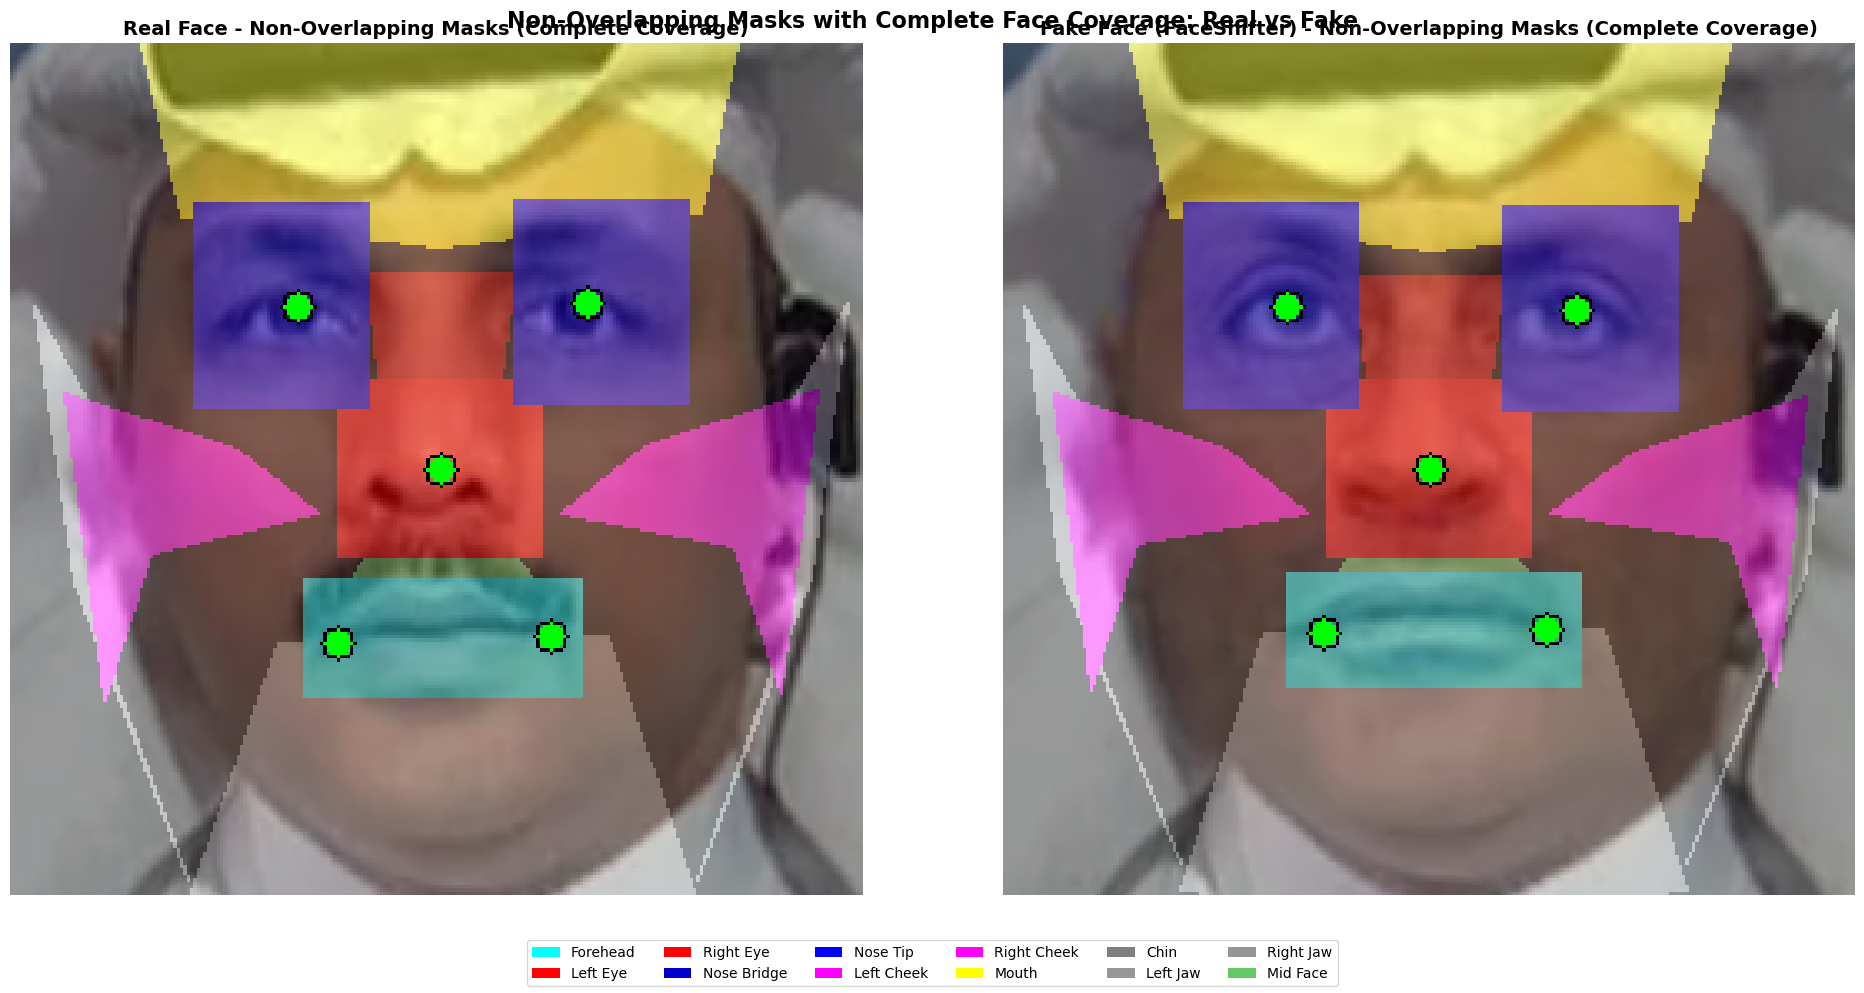

In [30]:
# Visualize Non-Overlapping Masks with Complete Coverage
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

real_vis_no = visualize_masks_on_image(real_img_first, real_masks_no_overlap_complete, 
                                        REGION_CONFIG_COMPLETE, real_median_landmarks, 'Real')
fake_vis_no = visualize_masks_on_image(fake_img_first, fake_masks_no_overlap_complete, 
                                        REGION_CONFIG_COMPLETE, fake_median_landmarks, 'Fake')

axes[0].imshow(cv2.cvtColor(real_vis_no, cv2.COLOR_BGR2RGB))
axes[0].set_title('Real Face - Non-Overlapping Masks (Complete Coverage)', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(fake_vis_no, cv2.COLOR_BGR2RGB))
axes[1].set_title('Fake Face (FaceShifter) - Non-Overlapping Masks (Complete Coverage)', fontsize=14, fontweight='bold')
axes[1].axis('off')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=np.array(config['color'])/255, label=name.replace('_', ' ').title())
    for name, config in REGION_CONFIG_COMPLETE.items()
]
fig.legend(handles=legend_elements, loc='lower center', ncol=6, fontsize=10)

plt.suptitle('Non-Overlapping Masks with Complete Face Coverage: Real vs Fake', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

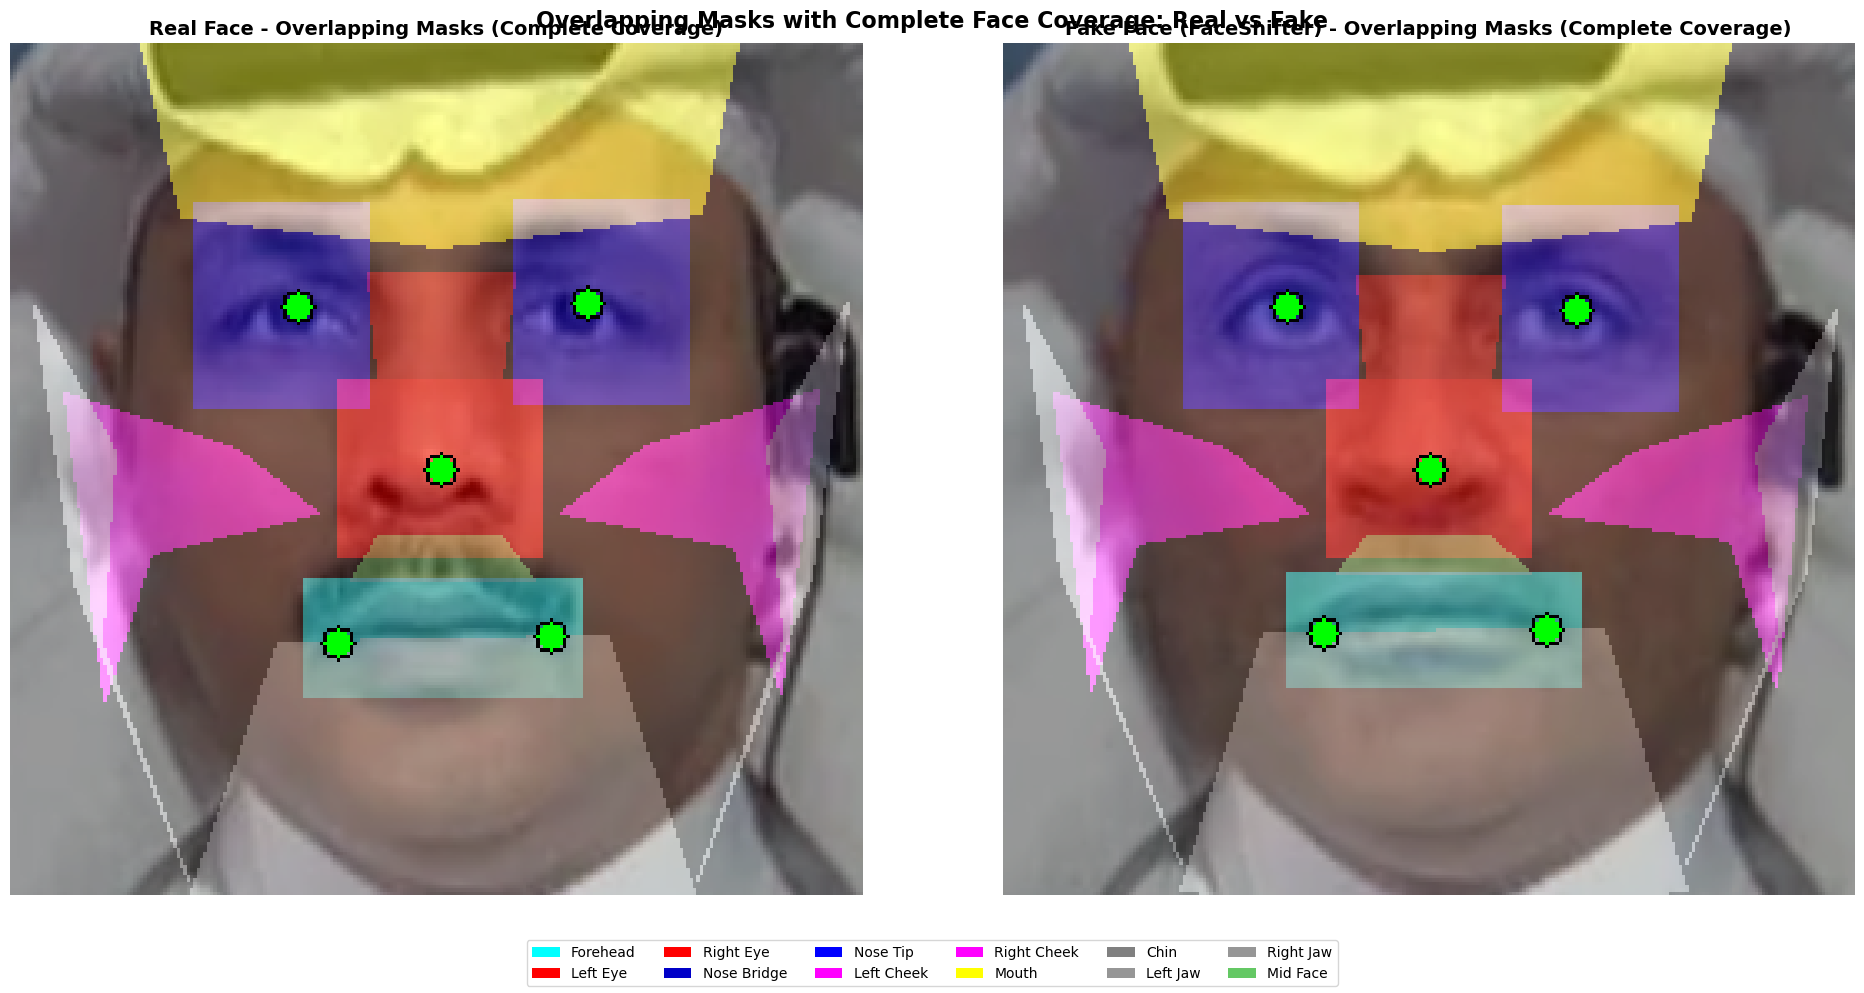

In [32]:
# Visualize Overlapping Masks with Complete Coverage
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

real_vis_ov = visualize_masks_on_image(real_img_first, real_masks_overlap_complete, 
                                        REGION_CONFIG_COMPLETE, real_median_landmarks, 'Real')
fake_vis_ov = visualize_masks_on_image(fake_img_first, fake_masks_overlap_complete, 
                                        REGION_CONFIG_COMPLETE, fake_median_landmarks, 'Fake')

axes[0].imshow(cv2.cvtColor(real_vis_ov, cv2.COLOR_BGR2RGB))
axes[0].set_title('Real Face - Overlapping Masks (Complete Coverage)', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(fake_vis_ov, cv2.COLOR_BGR2RGB))
axes[1].set_title('Fake Face (FaceShifter) - Overlapping Masks (Complete Coverage)', fontsize=14, fontweight='bold')
axes[1].axis('off')

fig.legend(handles=legend_elements, loc='lower center', ncol=6, fontsize=10)

plt.suptitle('Overlapping Masks with Complete Face Coverage: Real vs Fake', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

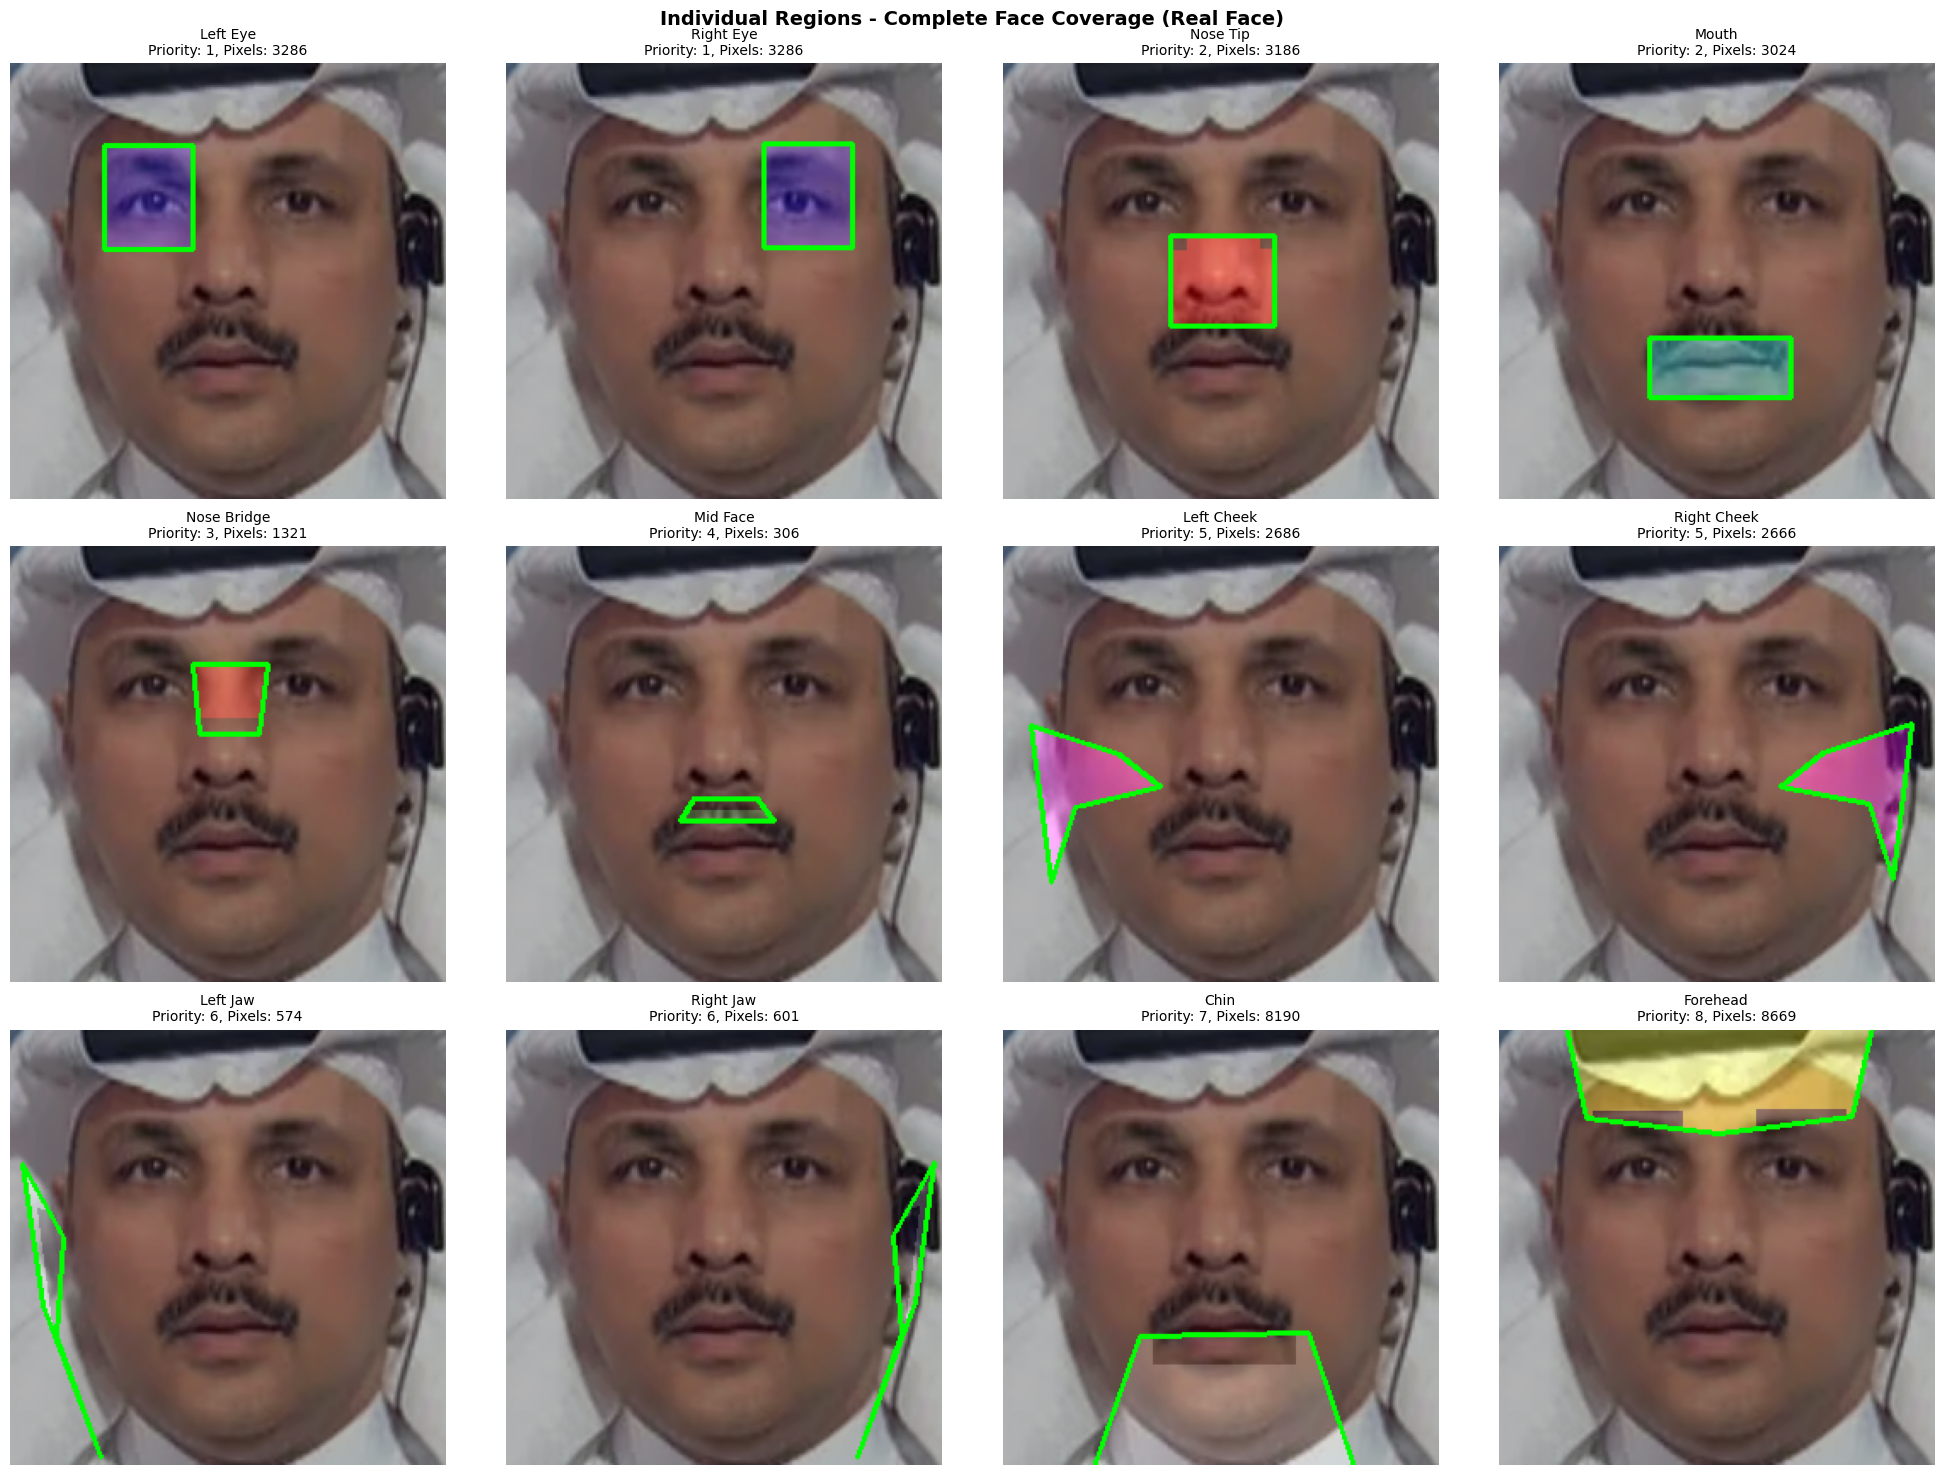

In [34]:
# Individual Region Visualization with Complete Coverage
n_regions = len(real_masks_no_overlap_complete)
n_cols = 4
n_rows = (n_regions + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
axes = axes.flatten()

for idx, (region_name, mask) in enumerate(real_masks_no_overlap_complete.items()):
    ax = axes[idx]
    
    vis_image = real_img_first.copy()
    colored_mask = np.zeros_like(vis_image)
    color = REGION_CONFIG_COMPLETE[region_name]['color']
    colored_mask[mask > 0] = color
    result = cv2.addWeighted(vis_image, 0.7, colored_mask, 0.3, 0)
    
    # Draw region polygon boundary
    region_polygons = create_complete_face_regions(real_median_landmarks, real_image_shape)
    if region_name in region_polygons:
        points = region_polygons[region_name]
        cv2.polylines(result, [points], True, (0, 255, 0), 2)
    
    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    priority = REGION_CONFIG_COMPLETE[region_name]['priority']
    pixel_count = np.sum(mask > 0)
    ax.set_title(f'{region_name.replace("_", " ").title()}\nPriority: {priority}, Pixels: {pixel_count}', 
                fontsize=10)
    ax.axis('off')


plt.suptitle('Individual Regions - Complete Face Coverage (Real Face)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/retinaface_complete_overlap_heatmap.png'

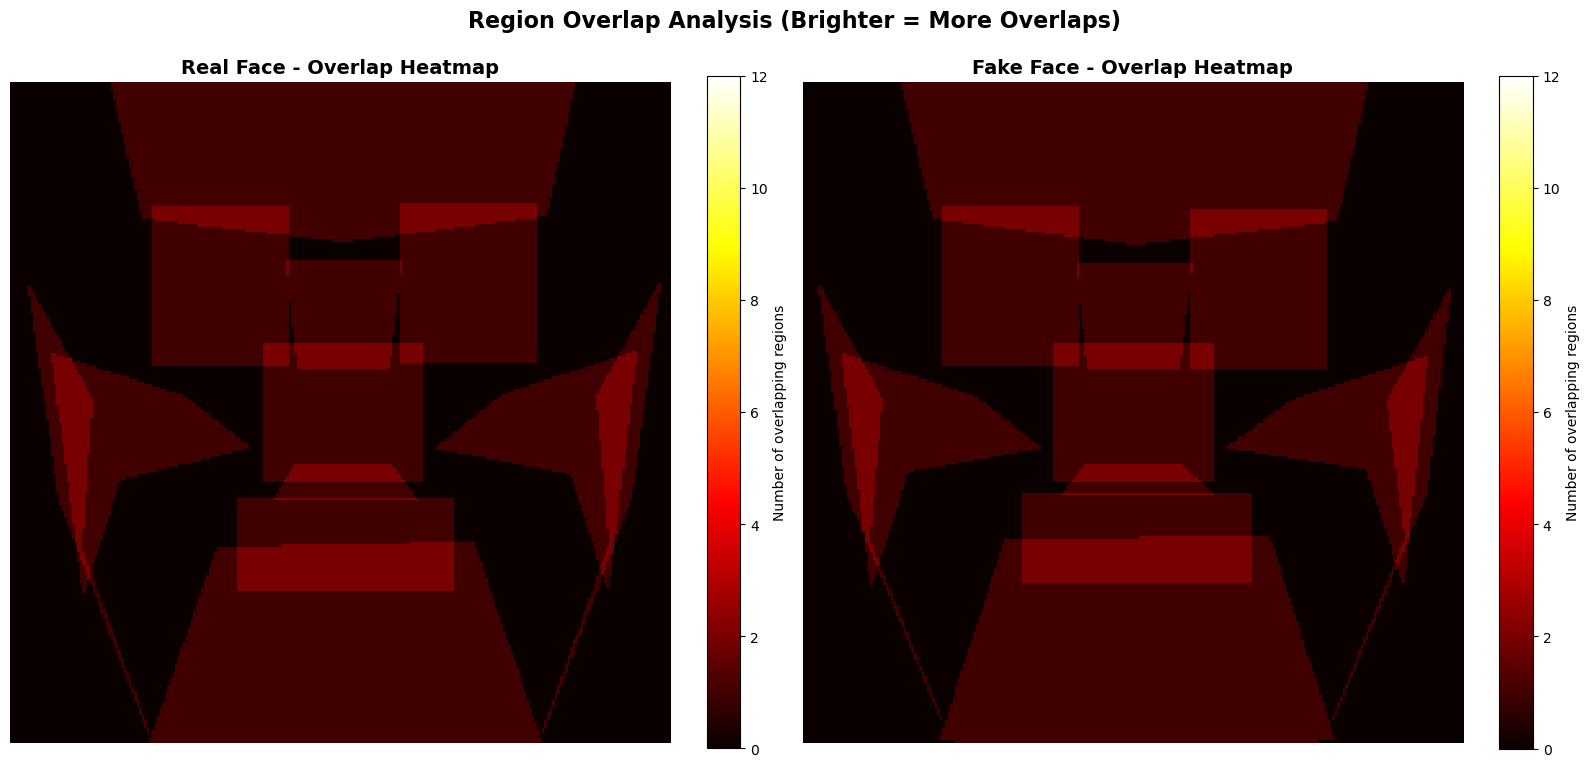

In [35]:
# Overlap Heatmap for Complete Coverage
real_overlap_count = np.zeros(real_image_shape[:2], dtype=np.uint8)
fake_overlap_count = np.zeros(fake_image_shape[:2], dtype=np.uint8)

for mask in real_masks_overlap_complete.values():
    real_overlap_count += (mask > 0).astype(np.uint8)

for mask in fake_masks_overlap_complete.values():
    fake_overlap_count += (mask > 0).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

im0 = axes[0].imshow(real_overlap_count, cmap='hot', interpolation='nearest', vmin=0, vmax=12)
axes[0].set_title('Real Face - Overlap Heatmap', fontsize=14, fontweight='bold')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], label='Number of overlapping regions', fraction=0.046)

im1 = axes[1].imshow(fake_overlap_count, cmap='hot', interpolation='nearest', vmin=0, vmax=12)
axes[1].set_title('Fake Face - Overlap Heatmap', fontsize=14, fontweight='bold')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], label='Number of overlapping regions', fraction=0.046)

plt.suptitle('Region Overlap Analysis (Brighter = More Overlaps)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('/mnt/user-data/outputs/retinaface_complete_overlap_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Overlap statistics
print("\n=== Overlap Distribution (Real Face) ===")
unique_real, counts_real = np.unique(real_overlap_count, return_counts=True)
for num_regions, pixel_count in zip(unique_real, counts_real):
    if num_regions > 0:
        pct = pixel_count / np.sum(counts_real) * 100
        print(f"{num_regions:2d} region(s): {pixel_count:>7} pixels ({pct:>5.2f}%)")

print("\n=== Overlap Distribution (Fake Face) ===")
unique_fake, counts_fake = np.unique(fake_overlap_count, return_counts=True)
for num_regions, pixel_count in zip(unique_fake, counts_fake):
    if num_regions > 0:
        pct = pixel_count / np.sum(counts_fake) * 100
        print(f"{num_regions:2d} region(s): {pixel_count:>7} pixels ({pct:>5.2f}%)")